# 2. 波动率会"记仇"：EWMA 和 GARCH

**这一本要回答的问题：** 第 1 本里的历史模拟法把 20 年前和昨天一视同仁。可是直觉告诉我们：**昨天刚暴跌过，明天大概率也不平静**。怎么让风险估计"跟上"市场的情绪？

顺序还是：直觉 → 真实数据手算 → 动手调参数 → 公式。

In [1]:
from learn_utils import *
from mre.models.ewma import ewma_variance, ewma_neg_loglik, fit_ewma_lambda
from mre.models.garch import fit_garch

cfg, asset_rets, port = load_portfolio()
r = port                                   # 组合的日收益率（小数，0.01 = 1%）
print(f"{len(r)} 天，{r.index[0].date()} 到 {r.index[-1].date()}")

5030 天，2006-01-04 到 2025-12-31


## 第 1 步：先用眼睛看——大波动是扎堆出现的

下图是每天收益率的绝对值（不管涨跌，只看动得多大）。

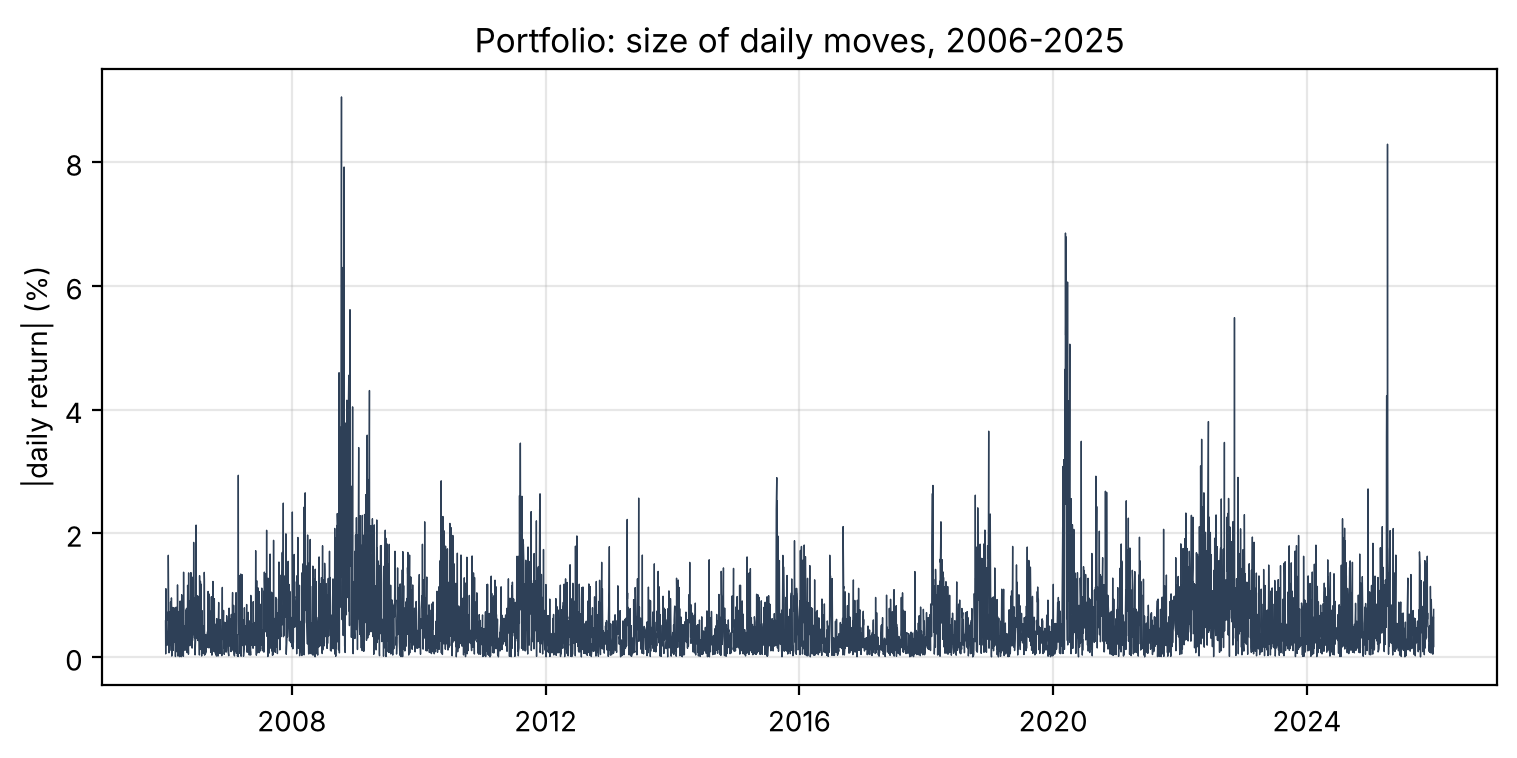

In [2]:
fig, ax = plt.subplots()
ax.plot(r.index, r.abs() * 100, lw=0.5, color="#2e4057")
ax.set_ylabel("|daily return| (%)"); ax.set_title("Portfolio: size of daily moves, 2006-2025")
plt.show()

2008 年和 2020 年是一大片"山"，2017 年几乎是平地。这个现象叫**波动率聚集**：大波动后面跟着大波动，小波动后面跟着小波动。

所以一个好的"明天波动率"估计应该：
- **主要参考最近**发生了什么；
- 但也**不能完全忘掉过去**。

## 第 2 步：EWMA 的直觉——一个有"记性"的平均

EWMA（指数加权移动平均）每天收盘后只做一件事：

> **新的估计 = λ × 旧的估计 + (1 − λ) × 今天收益的平方**

- **λ（读作 lambda）** 是一个 0 到 1 之间的数，代表"记性"。
- λ = 0.94：新估计里 94% 来自"昨天的看法"，6% 来自"今天发生了什么"。
- λ 越接近 1，记性越长、反应越慢；λ 越小，越"健忘"、反应越快。
- 为什么用收益的**平方**？因为方差（波动率的平方）就是"偏离的平方"的平均。平方之后涨跌都变成正数，只衡量"动得多大"。

一个好记的量：**半衰期** = 一个冲击的影响衰减到一半需要几天。

In [3]:
for lam in [0.80, 0.90, 0.94, 0.97, 0.99]:
    half_life = np.log(0.5) / np.log(lam)
    print(f"lambda = {lam:.2f}  ->  半衰期约 {half_life:5.1f} 天")

lambda = 0.80  ->  半衰期约   3.1 天
lambda = 0.90  ->  半衰期约   6.6 天
lambda = 0.94  ->  半衰期约  11.2 天
lambda = 0.97  ->  半衰期约  22.8 天
lambda = 0.99  ->  半衰期约  69.0 天


## 第 3 步：手算 2020 年 3 月的几天

下面用 λ = 0.94，从 2020-02-21 开始一天一天手算。起点的"旧估计"直接用仓库的 `ewma_variance` 在那之前的数据上算出来，后面每一步都用上面那一句话更新。

In [4]:
lam = 0.94
start = r.index.get_loc(pd.Timestamp("2020-02-21"))
hist = r.iloc[:start]                             # 只用 2020-02-21 之前的数据
_, s2 = ewma_variance(hist.values, lam)           # 仓库函数给出"对 2020-02-21 的方差预测"

rows = []
for t in range(start, start + 12):
    ret = r.iloc[t]
    new_s2 = lam * s2 + (1 - lam) * ret**2        # 就是那一句话
    rows.append({"日期": r.index[t].date(), "今天收益": f"{ret:+.2%}",
                 "早上的波动率估计(日)": f"{np.sqrt(s2):.2%}",
                 "收盘后更新为(日)": f"{np.sqrt(new_s2):.2%}",
                 "折成年化": f"{np.sqrt(new_s2 * 252):.0%}"})
    s2 = new_s2
pd.DataFrame(rows)

,日期,今天收益,早上的波动率估计(日),收盘后更新为(日),折成年化
0,2020-02-21,-0.65%,0.45%,0.47%,7%
1,2020-02-24,-2.10%,0.47%,0.68%,11%
2,2020-02-25,-2.10%,0.68%,0.84%,13%
3,2020-02-26,-0.05%,0.84%,0.81%,13%
4,2020-02-27,-3.08%,0.81%,1.09%,17%
5,2020-02-28,-0.06%,1.09%,1.06%,17%
6,2020-03-02,+3.19%,1.06%,1.29%,20%
7,2020-03-03,-1.48%,1.29%,1.30%,21%
8,2020-03-04,+2.74%,1.30%,1.43%,23%
9,2020-03-05,-1.53%,1.43%,1.44%,23%


看"收盘后更新为"这一列：2 月下旬连续出现 2%–3% 的大跌，估计一路往上爬，到 3 月 9 日已经接近起点的 4 倍。EWMA 不需要任何人告诉它"危机来了"，它自己从每天的收益里就"感觉"到了。

（年化 = 日波动率 × √252，252 是一年大约的交易日数，只是为了方便和"年化波动率 15%"这种说法对比。）

我们再核对一下：手算的最后一个数，和仓库函数直接算出来的一样吗？

In [5]:
_, repo_s2 = ewma_variance(r.iloc[:start + 12].values, lam)
print(f"手算:     {np.sqrt(s2):.6%}")
print(f"仓库函数: {np.sqrt(repo_s2):.6%}")

手算:     1.765996%
仓库函数: 1.765996%


## 第 4 步：🎛️ 调 λ，看反应速度

下图是 2019 下半年到 2020 年底。灰点是每天实际动了多少，彩色线是 EWMA 每天早上给出的波动率估计。

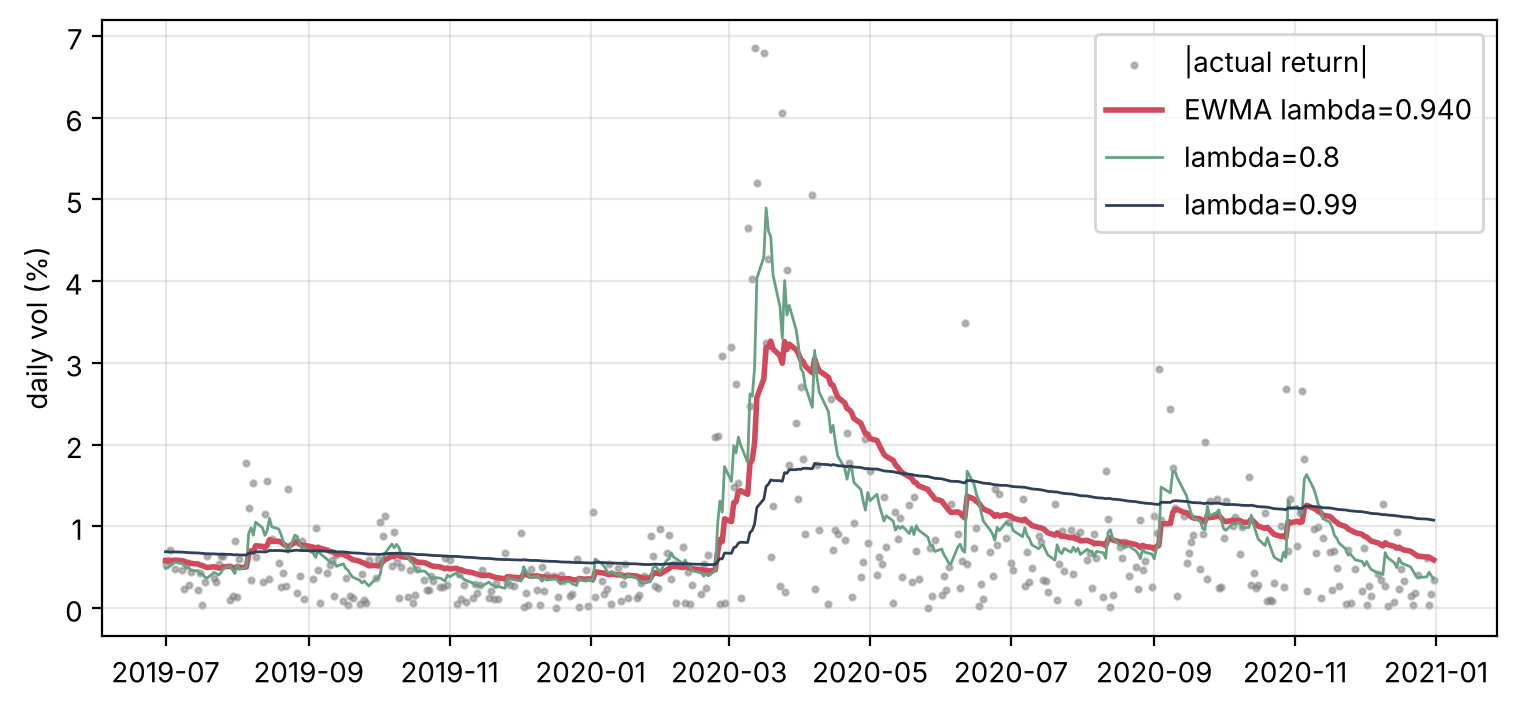

lambda=0.940: 估计最高点 3.27% 出现在 2020-03-19；2020-12-31 时还剩 0.59%


In [6]:
def show_lambda(lam=0.94, compare=True):
    s2, _ = ewma_variance(r.values, lam)
    vol = pd.Series(np.sqrt(s2), index=r.index)
    seg = slice("2019-07-01", "2020-12-31")
    fig, ax = plt.subplots()
    ax.scatter(r[seg].index, r[seg].abs() * 100, s=4, color="grey", alpha=0.5, label="|actual return|")
    ax.plot(vol[seg].index, vol[seg] * 100, lw=2, color="#d1495b", label=f"EWMA lambda={lam:.3f}")
    if compare:
        for other, c in [(0.80, "#66a182"), (0.99, "#2e4057")]:
            v2 = pd.Series(np.sqrt(ewma_variance(r.values, other)[0]), index=r.index)
            ax.plot(v2[seg].index, v2[seg] * 100, lw=1, color=c, label=f"lambda={other}")
    ax.set_ylabel("daily vol (%)"); ax.legend(); plt.show()
    peak = vol[seg].idxmax()
    print(f"lambda={lam:.3f}: 估计最高点 {vol[seg].max():.2%} 出现在 {peak.date()}；"
          f"2020-12-31 时还剩 {vol['2020-12-31']:.2%}")

show_lambda(0.94)

- **λ = 0.80**（绿）：跳得最快，但也忘得最快，平静一点就马上掉下来，线很"毛躁"。
- **λ = 0.99**（深蓝）：非常迟钝，3 月最危险的时候还没涨上去，等危机过了它还高高挂着。
- **λ = 0.94** 介于两者之间。

试试拖到 0.85 和 0.97，看最高点出现的日期怎么变。

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ lam = 0.85，compare = False


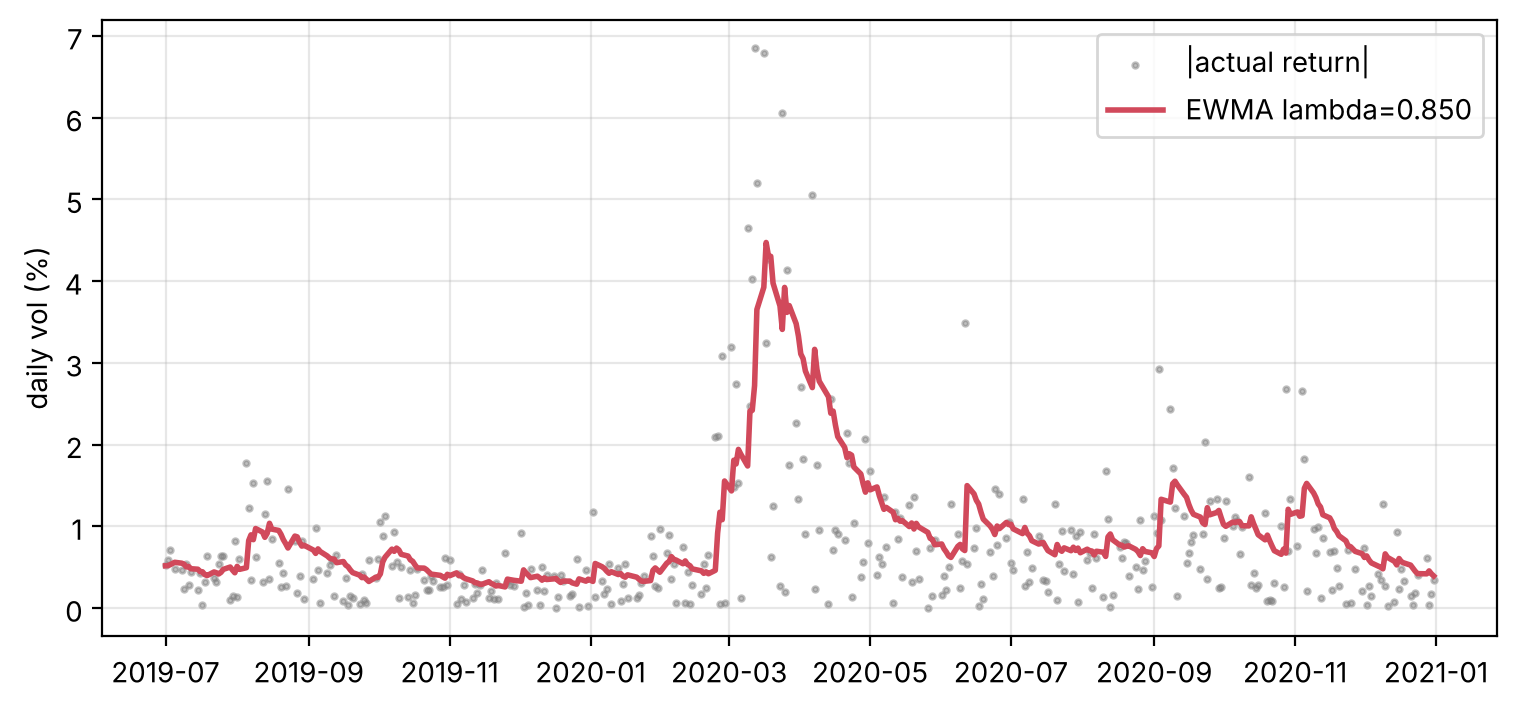

lambda=0.850: 估计最高点 4.47% 出现在 2020-03-17；2020-12-31 时还剩 0.39%

▶ lam = 0.97，compare = False


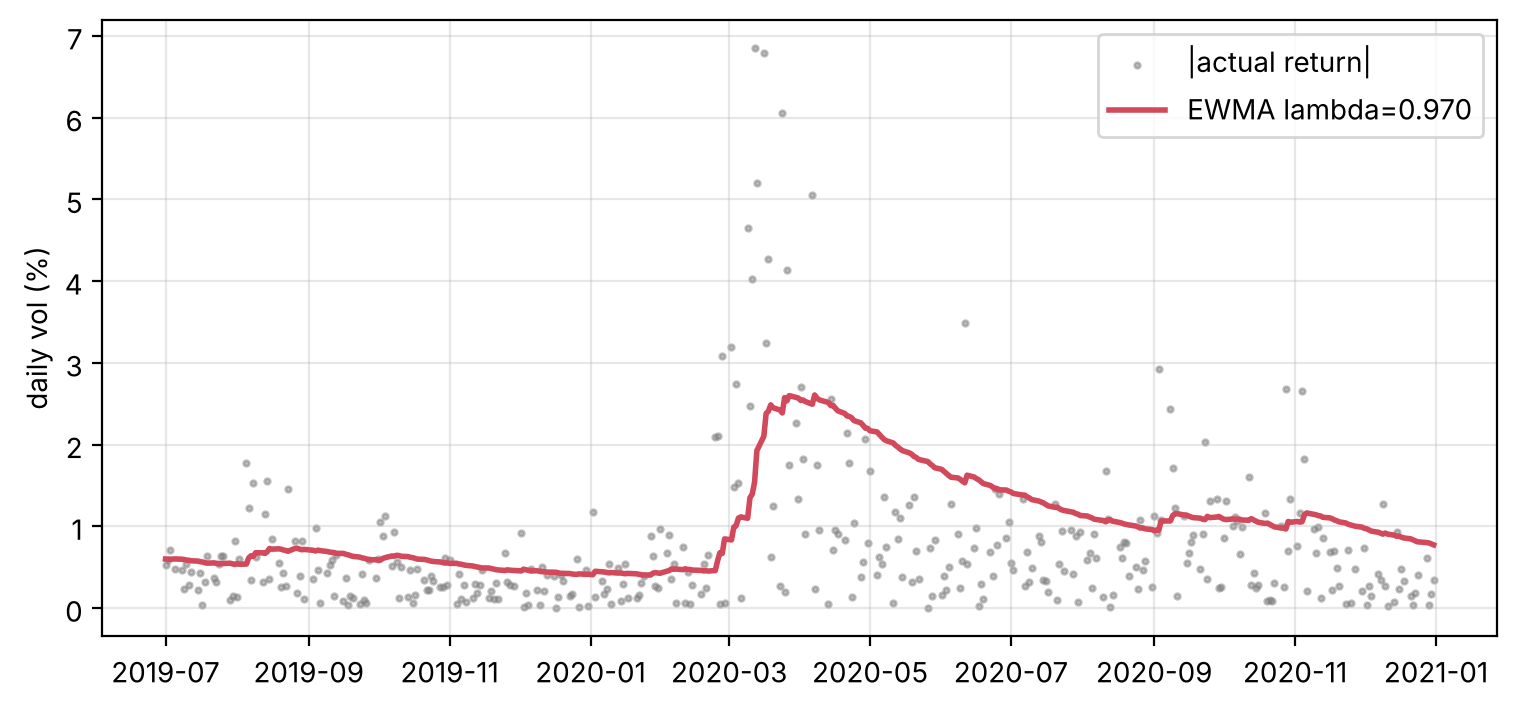

lambda=0.970: 估计最高点 2.61% 出现在 2020-04-07；2020-12-31 时还剩 0.77%


In [7]:
play(show_lambda, examples=[{"lam": 0.85, "compare": False}, {"lam": 0.97, "compare": False}],
     lam=(0.80, 0.995, 0.005), compare=True)

## 第 5 步：λ 不用拍脑袋——让数据自己选

仓库里 λ 是用**最大似然**选的。听起来吓人，意思其实很简单：

> 给每个候选 λ 打分。每天，模型先说"明天波动率大概是 σ"；第二天真实收益揭晓。如果模型说"很平静"结果来了个大跌，**扣很多分**；如果模型说"很危险"结果风平浪静，**也扣分**（不过扣得少一些）。把 500 天的扣分加起来，**扣分最少的 λ 胜出**。

仓库的 `ewma_neg_loglik` 就是这个"扣分表"（"负对数似然"，越小越好）。下面在最近 500 天上把每个 λ 的分数画出来：

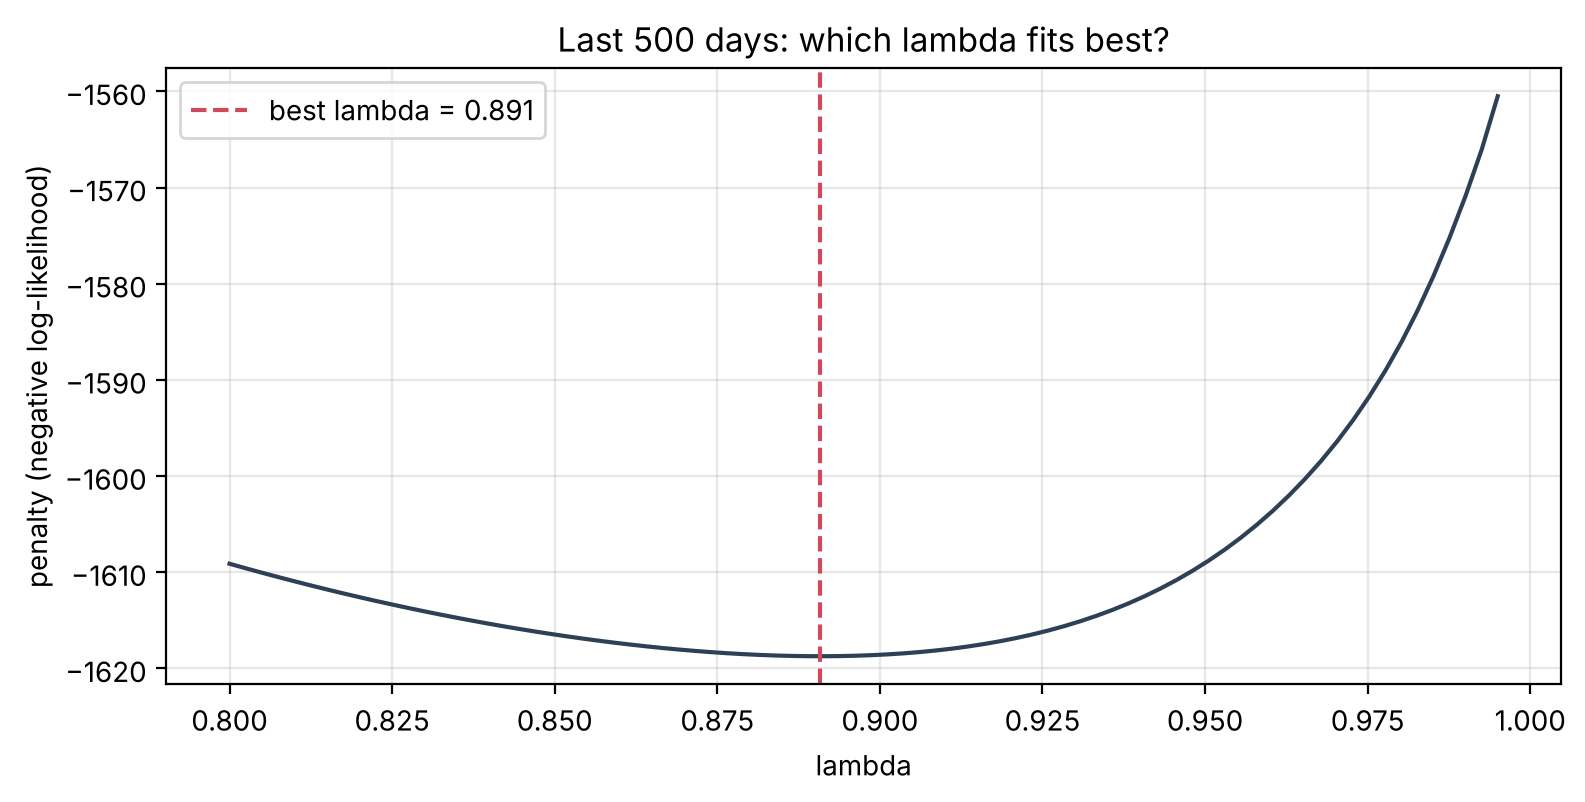

最近 500 天里，数据选出的 lambda = 0.8908（半衰期 6.0 天）


In [8]:
window = r.iloc[-500:].values
grid = np.linspace(0.80, 0.995, 80)
scores = [ewma_neg_loglik(l, window) for l in grid]
best = fit_ewma_lambda(window)          # 仓库函数：自动找最低点

fig, ax = plt.subplots()
ax.plot(grid, scores, color="#2e4057")
ax.axvline(best.lam, color="#d1495b", ls="--", label=f"best lambda = {best.lam:.3f}")
ax.set_xlabel("lambda"); ax.set_ylabel("penalty (negative log-likelihood)")
ax.set_title("Last 500 days: which lambda fits best?"); ax.legend(); plt.show()
print(f"最近 500 天里，数据选出的 lambda = {best.lam:.4f}（半衰期 {np.log(.5)/np.log(best.lam):.1f} 天）")

在 Phase 3 的滚动回测里，仓库每 21 个交易日就用最近 500 天重新选一次 λ。下面直接读回测结果，看 2009–2025 年 λ 都选成了多少：

一共 4030 天预测；lambda 中位数 0.9199，最小 0.8461，最大 0.9995


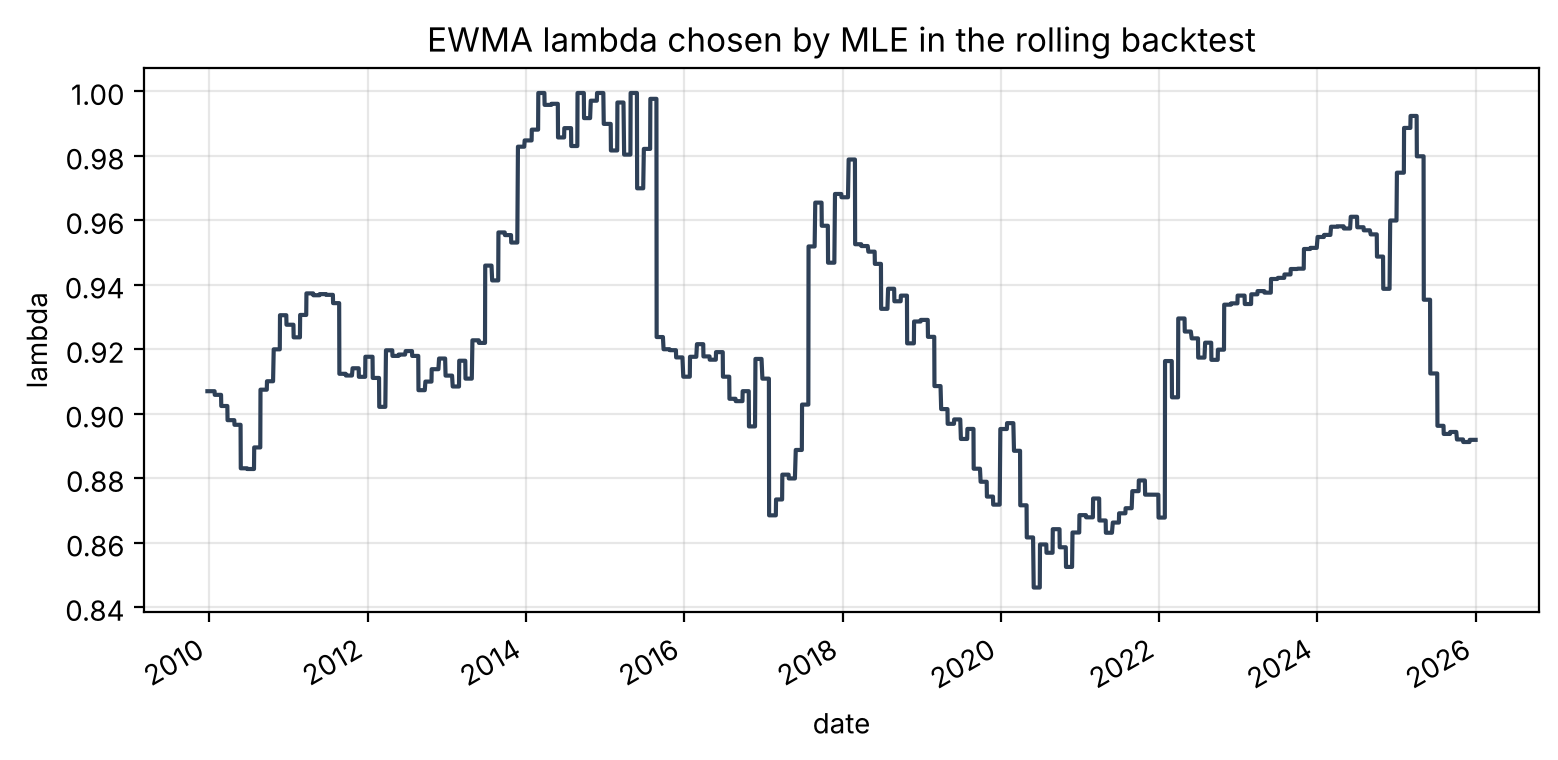

In [9]:
ew = load_forecasts("EWMA, W=500")
print(f"一共 {len(ew)} 天预测；lambda 中位数 {ew['lambda'].median():.4f}，"
      f"最小 {ew['lambda'].min():.4f}，最大 {ew['lambda'].max():.4f}")
ax = ew["lambda"].plot(title="EWMA lambda chosen by MLE in the rolling backtest", color="#2e4057")
ax.set_ylabel("lambda"); plt.show()

中位数约 0.92，和"教科书值" 0.94（J.P. Morgan RiskMetrics 1996 年给的）挺接近，但不同时期确实差很多。

## 第 6 步：GARCH——给 EWMA 加一个"长期平均"的锚

EWMA 有一个小毛病：**如果明天开始一直很平静，它的预测会一直往下掉，没有底**；而且它预测"10 天以后的波动率"和"明天的"是一样的。现实中波动率会**回归**到一个长期正常水平。

GARCH(1,1) 只是在 EWMA 那句话上多加了一项：

> **新的估计 = ω（一个很小的常数）+ α × 今天收益的平方 + β × 旧的估计**

- **α（alpha）**：对"今天的冲击"有多敏感，相当于 EWMA 里的 1 − λ。
- **β（beta）**：记性，相当于 EWMA 里的 λ。
- **ω（omega）**：一个常数，它把估计往**长期平均水平**拉。
- **α + β** 叫"持续性"：越接近 1，冲击消散得越慢。EWMA 其实就是 α + β = 1、ω = 0 的特例。

下面用仓库的 `fit_garch`，在 2020-04-01 之前的 500 天上拟合一个 GARCH-t（仓库 Phase 3 用的就是 500 天窗口）：

In [10]:
end = r.index.get_loc(pd.Timestamp("2020-04-01"))
fit = fit_garch(r.iloc[end - 500:end].values, dist="t", vol="garch")   # 只用 4 月 1 日以前
print(f"训练数据：{r.index[end-500].date()} 到 {r.index[end-1].date()}（500 天）")
print(f"alpha（对冲击的敏感度） = {fit.alpha:.3f}")
print(f"beta （记性）           = {fit.beta:.3f}")
print(f"alpha + beta（持续性）  = {fit.persistence:.4f}，半衰期约 {fit.half_life_days:.0f} 天")
print(f"长期平均波动率          = {fit.long_run_vol:.2%}/天（年化 {fit.long_run_vol * np.sqrt(252):.1%}）")
print(f"对 2020-04-01 的预测    = {fit.next_sigma:.2%}/天（年化 {fit.next_sigma * np.sqrt(252):.1%}）")

训练数据：2018-04-06 到 2020-03-31（500 天）
alpha（对冲击的敏感度） = 0.211
beta （记性）           = 0.781
alpha + beta（持续性）  = 0.9925，半衰期约 92 天
长期平均波动率          = 1.50%/天（年化 23.8%）
对 2020-04-01 的预测    = 2.81%/天（年化 44.6%）


注意：这个 500 天窗口里包含了 2020 年 3 月的暴跌，所以估出来的"长期平均"（年化约 24%）明显高于整个 20 年的实际年化波动率（Phase 1 报告里是 13.77%）。**参数取决于你给它看哪段数据**，这也是仓库要每 21 天重新拟合一次的原因。

### 往后看 60 天：GARCH 会"回家"，EWMA 不会

假设从 4 月 1 日起不再有新消息，两个模型对未来每一天的波动率怎么看？

- GARCH：每过一天，"离长期平均的距离"乘以一次 α + β，慢慢回到长期水平。
- EWMA：没有长期水平，未来每天的预测都和明天一样（一条水平线）。

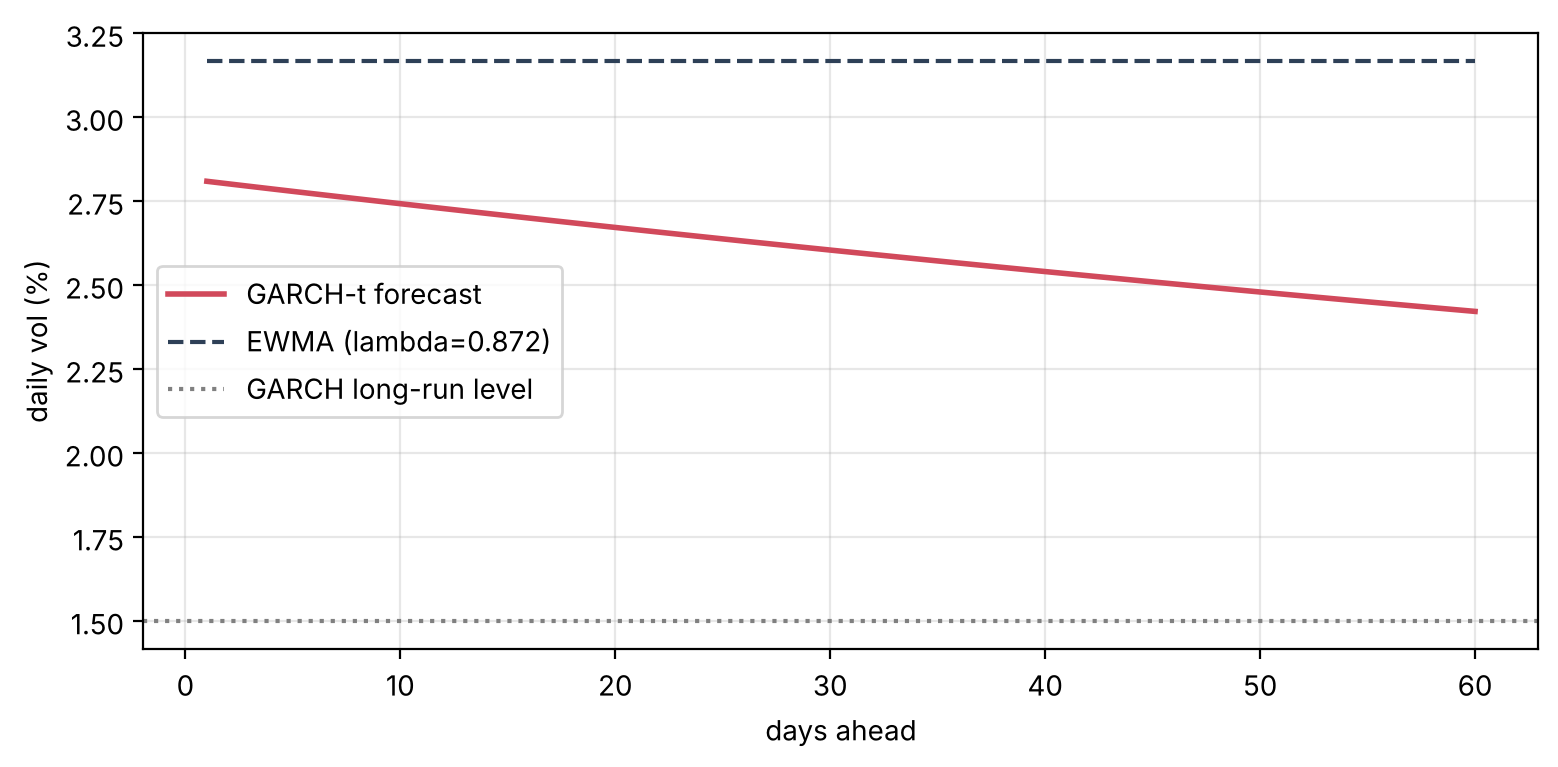

In [11]:
def forecast_path(fit, horizon=60):
    # 多步预测：sigma2[h+1] = omega + (alpha+beta) * sigma2[h]   （没有新冲击时，冲击的期望就是方差本身）
    s2 = [fit.next_sigma**2]
    for _ in range(horizon - 1):
        s2.append(fit.omega + fit.persistence * s2[-1])
    return np.sqrt(s2)

lam_mle = fit_ewma_lambda(r.iloc[end - 500:end].values)
ewma_next = np.sqrt(ewma_variance(r.iloc[end - 500:end].values, lam_mle.lam)[1])

h = np.arange(1, 61)
fig, ax = plt.subplots()
ax.plot(h, forecast_path(fit) * 100, color="#d1495b", lw=2, label="GARCH-t forecast")
ax.plot(h, np.full(60, ewma_next * 100), color="#2e4057", ls="--", label=f"EWMA (lambda={lam_mle.lam:.3f})")
ax.axhline(fit.long_run_vol * 100, color="grey", ls=":", label="GARCH long-run level")
ax.set_xlabel("days ahead"); ax.set_ylabel("daily vol (%)"); ax.legend(); plt.show()

### 🎛️ 参数实验室

下面把 α、β 当成旋钮，从同一个起点（"今天刚经历了一次冲击，明天的波动率是长期水平的 3 倍"）出发，看它多久"回家"。
试试：
1. 让 α + β 非常接近 1（比如 β = 0.989，α = 0.01），回家要多久？
2. α 加大、β 减小（总和不变），对"回家速度"有影响吗？（提示：多步预测里只出现了 α + β。α 大小影响的是"冲击来的那一下跳多高"。）

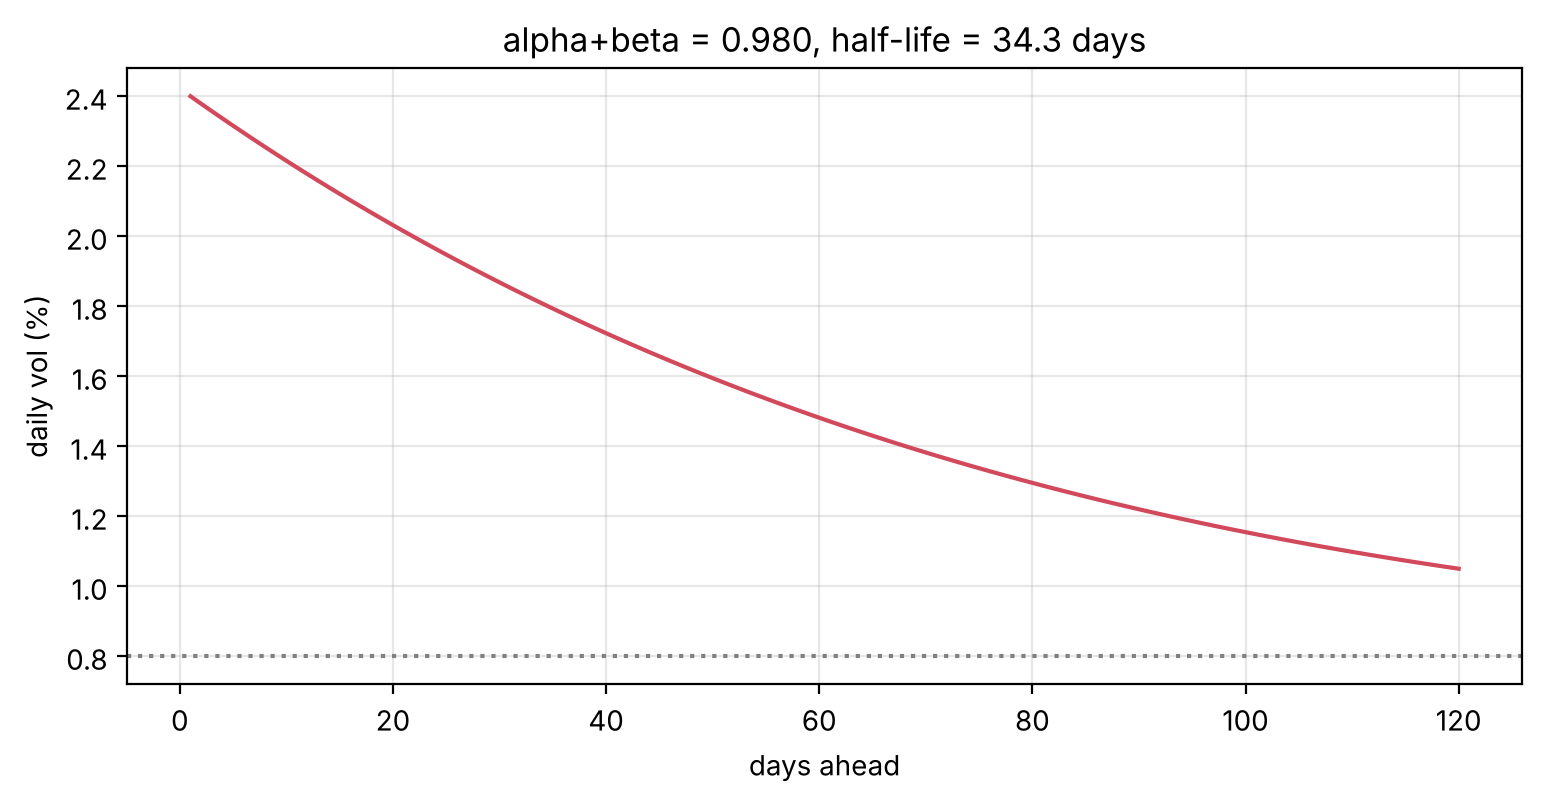

In [12]:
def garch_lab(alpha=0.10, beta=0.88, start_multiple=3.0, long_run_daily_vol=0.008):
    p = alpha + beta
    if p >= 1:
        print("alpha + beta >= 1：没有长期平均水平了（像 EWMA 一样不会回家），请调小一点。")
        return
    omega = long_run_daily_vol**2 * (1 - p)            # 让长期水平正好是设定值
    s2 = [(start_multiple * long_run_daily_vol) ** 2]
    for _ in range(119):
        s2.append(omega + p * s2[-1])
    vol = np.sqrt(s2)
    fig, ax = plt.subplots()
    ax.plot(np.arange(1, 121), vol * 100, color="#d1495b")
    ax.axhline(long_run_daily_vol * 100, color="grey", ls=":")
    ax.set_xlabel("days ahead"); ax.set_ylabel("daily vol (%)")
    ax.set_title(f"alpha+beta = {p:.3f}, half-life = {np.log(.5)/np.log(p):.1f} days"); plt.show()

garch_lab(0.10, 0.88)

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ alpha = 0.01，beta = 0.989


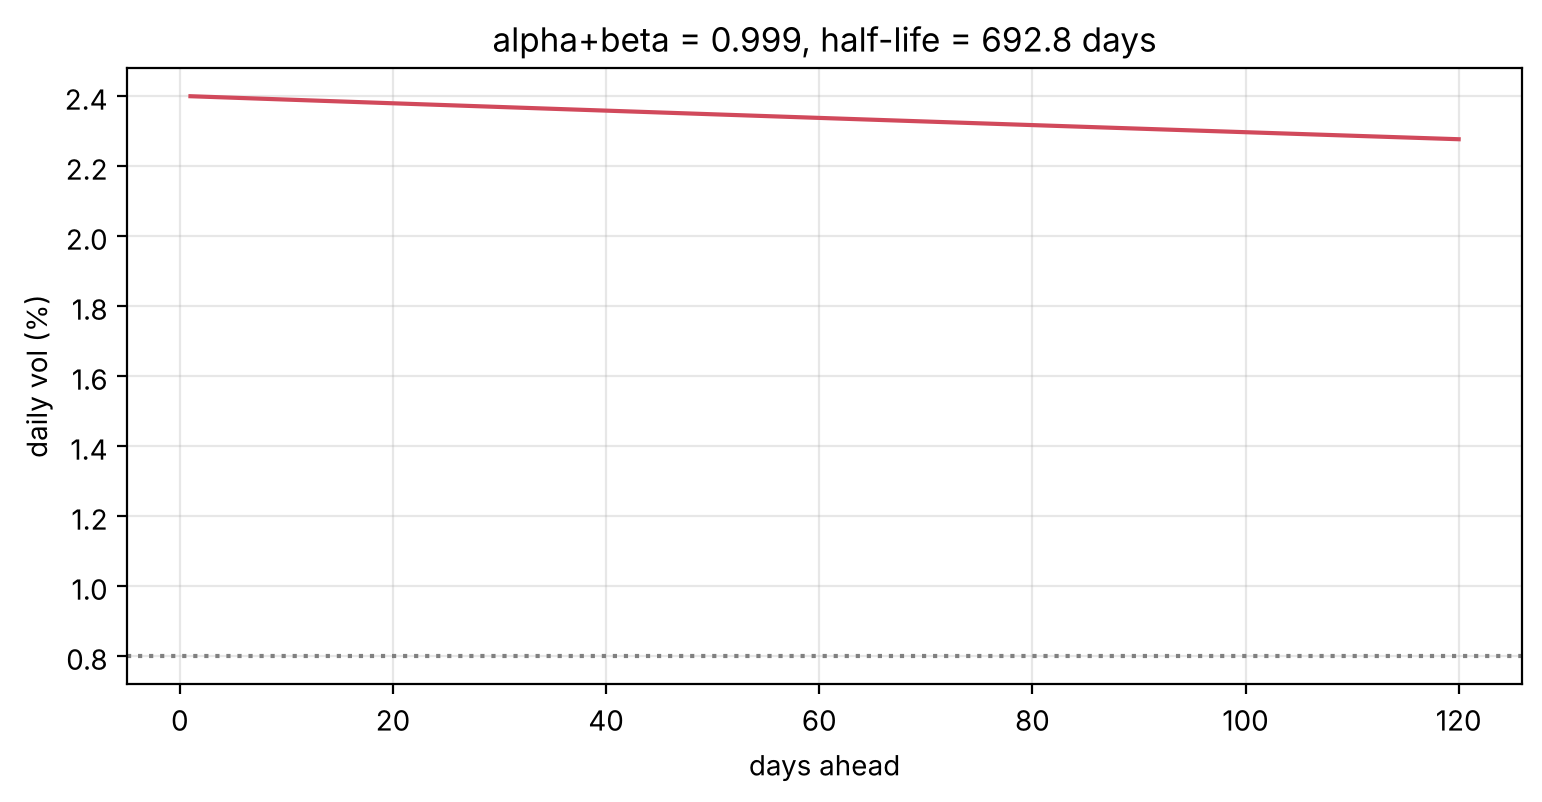


▶ alpha = 0.25，beta = 0.73


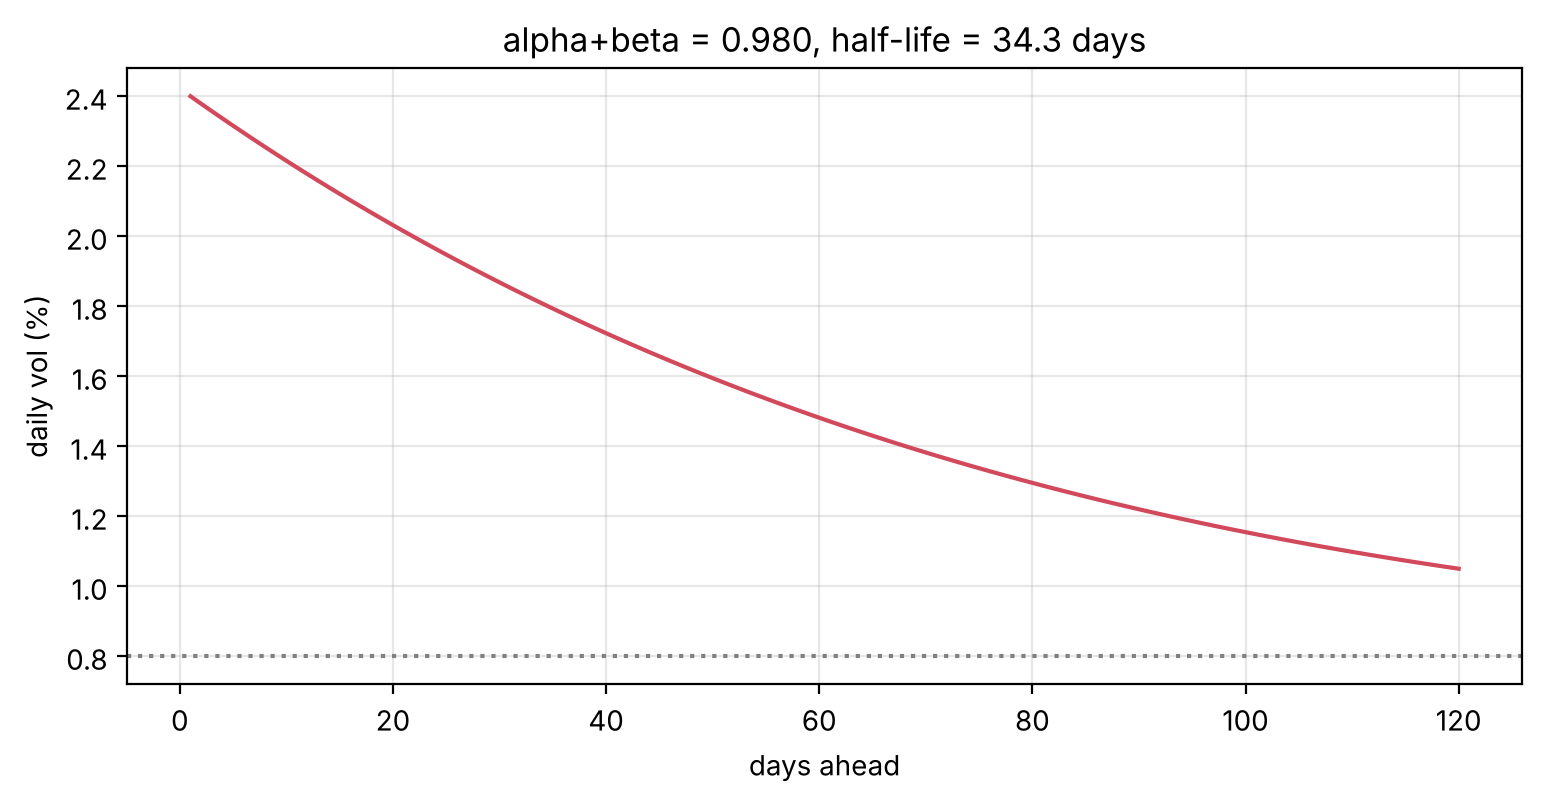

In [13]:
play(garch_lab, examples=[{"alpha": 0.01, "beta": 0.989}, {"alpha": 0.25, "beta": 0.73}],
     alpha=(0.0, 0.3, 0.01), beta=(0.5, 0.995, 0.005),
     start_multiple=(1.0, 5.0, 0.5), long_run_daily_vol=(0.004, 0.015, 0.001))

## 最后：公式

| 符号 | 意思 |
|---|---|
| $r_t$ | 第 $t$ 天的收益率 |
| $\sigma_t$ | 第 $t$ 天开盘前，模型对"今天会动多大"的估计（波动率）；$\sigma_t^2$ 是它的平方，叫方差 |
| $\lambda$ | EWMA 的"记性" |
| $\omega, \alpha, \beta$ | GARCH 的三个参数：常数、对冲击的敏感度、记性 |

**EWMA：** 今天的估计 = 昨天的估计和昨天收益平方的加权平均

$$\sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1-\lambda)\,r_{t-1}^2$$

**GARCH(1,1)：** 多了一个常数 $\omega$，并且两个权重不必加起来等于 1

$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

这里 $\varepsilon_{t-1}$ 是昨天收益减去平均收益（仓库里 $\varepsilon = r - \mu$，$\mu$ 是很小的日均收益），基本可以当成 $r_{t-1}$。

**长期水平**（令 $\sigma_t^2 = \sigma_{t-1}^2 = \varepsilon^2$ 解出来）：$\;\bar\sigma^2 = \dfrac{\omega}{1-\alpha-\beta}$

**半衰期：** $\;\dfrac{\ln 0.5}{\ln(\alpha+\beta)}$（EWMA 就把 $\alpha+\beta$ 换成 $\lambda$）

注意下标：算第 $t$ 天的估计只用到 $t-1$ 及以前的数据，这就是仓库反复强调的"**没有前视偏差**"。

**对应代码：** `src/mre/models/ewma.py`（`ewma_variance` 就是第一行公式，`fit_ewma_lambda` 是第 5 步的打分），`src/mre/models/garch.py`（`fit_garch`，用 `arch` 包做最大似然）。

## 小练习

1. λ = 0.97 时，一个冲击过了 23 天还剩多少影响？
2. 如果拟合出来 α + β = 0.999，你会担心什么？
3. 为什么 GARCH 用 Student-t 分布（`dist="t"`）而不是正态分布？

<details><summary>点这里看参考答案</summary>

1. 0.97 的半衰期约 22.8 天，所以大约还剩一半。
2. 半衰期接近 700 天，几乎等于 EWMA，"长期平均"变得很不稳定、很难估准。Phase 3 报告里记录了：有 6.8% 的日子持续性 ≥ 0.999。
3. 即使按当天波动率标准化之后，收益的尾部还是比正态分布更"肥"（大跌比正态预言的更常见）。t 分布有一个"自由度"参数来调尾巴的肥瘦。第 3 本 notebook 会直接画出来。
</details>